# How are period and amplitude related?

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
from scipy import stats
from stats_toolkit import pearson_r

rr = pd.read_csv("../data/raw/gaia_dr3_rrlyrae_pilot_raw.csv")
rr["period"] = rr["pf"].fillna(rr["p1_o"])
rr["period_type"] = np.where(rr["pf"].notna(), "fundamental", "overtone")
rr["log_period"] = np.log10(rr["period"])
print(rr.shape)

(2000, 13)


In [2]:
fund = rr[rr["period_type"] == "fundamental"].dropna(subset=["log_period", "peak_to_peak_g"])

mine = pearson_r(fund["log_period"], fund["peak_to_peak_g"])
theirs = stats.pearsonr(fund["log_period"], fund["peak_to_peak_g"])[0]

print("n =", len(fund))
print("mine  :", mine)
print("scipy :", theirs)
print("difference:", abs(mine - theirs))

n = 1262
mine  : -0.3820991923788068
scipy : -0.38209919237880685
difference: 5.551115123125783e-17


In [3]:
from stats_toolkit import correlation_summary

res = correlation_summary(fund["log_period"], fund["peak_to_peak_g"])
for k, v in res.items():
    print(k, ":", v)

# check the interval against scipy
sp = stats.pearsonr(fund["log_period"], fund["peak_to_peak_g"])
print("scipy 95% CI:", sp.confidence_interval())

n : 1262
r : -0.3820991923788068
r2 : 0.1459997928165364
se : 0.02403965875881792
pe : 0.016214749832822686
ci95 : (np.float64(-0.42825196419373496), np.float64(-0.33395821716533786))
scipy 95% CI: ConfidenceInterval(low=np.float64(-0.42825113532491954), high=np.float64(-0.3339591189849056))


In [4]:
import pandas as pd

rr2 = rr.dropna(subset=["log_period", "peak_to_peak_g"])
groups = {
    "pooled": rr2,
    "fundamental": rr2[rr2["period_type"] == "fundamental"],
    "overtone": rr2[rr2["period_type"] == "overtone"],
}

rows = []
for name, d in groups.items():
    s = correlation_summary(d["log_period"], d["peak_to_peak_g"])
    rows.append({"group": name, "n": s["n"], "r": s["r"], "r2": s["r2"],
                 "ci_low": s["ci95"][0], "ci_high": s["ci95"][1]})

pd.DataFrame(rows).round(3)

,group,n,r,r2,ci_low,ci_high
0,pooled,2000,0.403,0.163,0.366,0.439
1,fundamental,1262,-0.382,0.146,-0.428,-0.334
2,overtone,738,0.218,0.047,0.148,0.285


pooled: slope 0.787 (scipy 0.787), intercept 0.820 (scipy 0.820)
fundamental: slope -1.526 (scipy -1.526), intercept 0.278 (scipy 0.278)
overtone: slope 0.347 (scipy 0.347), intercept 0.517 (scipy 0.517)


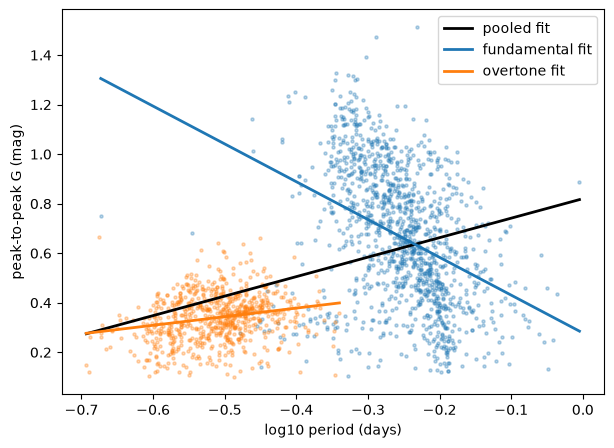

In [5]:
import matplotlib.pyplot as plt
from stats_toolkit import linear_fit

fig, ax = plt.subplots(figsize=(7, 5))
colors = {"fundamental": "tab:blue", "overtone": "tab:orange", "pooled": "black"}

for k in ["fundamental", "overtone"]:
    d = groups[k]
    ax.scatter(d["log_period"], d["peak_to_peak_g"], s=5, alpha=0.3, color=colors[k])

for name, d in groups.items():
    a, b = linear_fit(d["log_period"], d["peak_to_peak_g"])
    chk = stats.linregress(d["log_period"], d["peak_to_peak_g"])
    print(f"{name}: slope {b:.3f} (scipy {chk.slope:.3f}), intercept {a:.3f} (scipy {chk.intercept:.3f})")
    xs = np.linspace(d["log_period"].min(), d["log_period"].max(), 50)
    ax.plot(xs, a + b * xs, color=colors[name], lw=2, label=f"{name} fit")

ax.set_xlabel("log10 period (days)")
ax.set_ylabel("peak-to-peak G (mag)")
ax.legend()
plt.show()

In [6]:
from stats_toolkit import two_regression_lines

d = groups["fundamental"]
res2 = two_regression_lines(d["log_period"], d["peak_to_peak_g"])
for k, v in res2.items():
    print(k, ":", v)

print("pearson_r :", pearson_r(d["log_period"], d["peak_to_peak_g"]))

b_yx : -1.5262661614412965
b_xy : -0.09565814698968668
r2_from_slopes : 0.14599979281653638
r_from_slopes : -0.38209919237880674
pearson_r : -0.3820991923788068


In [7]:
from stats_toolkit import spearman_rho

for name, d in groups.items():
    x, y = d["log_period"], d["peak_to_peak_g"]
    print(name,
          "| pearson", round(pearson_r(x, y), 4),
          "| spearman mine", round(spearman_rho(x, y), 4),
          "| scipy", round(stats.spearmanr(x, y)[0], 4))

pooled | pearson 0.4031 | spearman mine 0.3665 | scipy 0.3665
fundamental | pearson -0.3821 | spearman mine -0.4424 | scipy -0.4424
overtone | pearson 0.2177 | spearman mine 0.2313 | scipy 0.2313


In [8]:
from stats_toolkit import polynomial_fit, poly_predict, r_squared, linear_fit

d = groups["fundamental"]
x = d["log_period"].to_numpy()          # log10 period
y = d["peak_to_peak_g"].to_numpy()      # amplitude (mag)
P = 10 ** x                             # period in days

rows = []

# polynomials in log10 period, checked against numpy
for deg, label in [(1, "line"), (2, "parabola"), (3, "cubic")]:
    c = polynomial_fit(x, y, deg)
    ok = np.allclose(c, np.polyfit(x, y, deg)[::-1])
    rows.append({"model": label, "R2": r_squared(y, poly_predict(c, x)), "matches numpy": ok})

# power law  y = A * P^B  (straight line in log-log)
a, b = linear_fit(x, np.log10(y))
rows.append({"model": "power law", "R2": r_squared(y, 10 ** (a + b * x)), "matches numpy": "n/a"})

# exponential  y = A * exp(k * P)  (straight line in ln y vs P)
a2, k = linear_fit(P, np.log(y))
rows.append({"model": "exponential", "R2": r_squared(y, np.exp(a2 + k * P)), "matches numpy": "n/a"})

pd.DataFrame(rows).round(4)

,model,R2,matches numpy
0,line,0.1460,True
1,parabola,0.1767,True
2,cubic,0.1845,True
3,power law,0.0754,n/a
4,exponential,0.1055,n/a
